First load nececary modules:

In [1]:
import math
from datetime import timedelta
from operator import attrgetter

import matplotlib.pyplot as plt
import numpy as np
import trajan as ta
import xarray as xr
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

import parcels

In [2]:
import math
from operator import attrgetter

import cmocean

from matplotlib import pyplot as plt,animation,rc
import numpy as np
import trajan as ta
import xarray as xr
import scipy.io
from scipy import interpolate
from datetime import datetime,timedelta
from IPython.display import HTML,Image
from netCDF4 import Dataset
rc('animation',html = 'html5')
from cartopy import crs,feature
import pandas as pd
#from matplotlib.animation import FuncAnimation

from parcels import (
    AdvectionRK4,
    AdvectionRK4_3D,
    FieldSet,
    JITParticle,
    ParticleSet,
    Variable,
    download_example_dataset,
    Field,
    GeographicPolar,
    Geographic
)

print("it worked")


it worked


In [3]:
# Import land mask, and try to fix stuck particles on coast
example_dataset_folder = "C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/BackwardTrajectoriesData"

# 1) load velocity fields:
uvdata = f"{example_dataset_folder}/cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1722998610742.nc"

# 2) create land mask:
#landmask = loadmat("mask_turtorial.mat")
# define meshgrid coordinates to plot velocity field with matplotlib pcolormesh

def make_landmask(fielddata):
    """Returns landmask where land = 1 and ocean = 0
    fielddata is a netcdf file.
    """
    datafile = Dataset(fielddata)

    landmask = datafile.variables["uo"][0, 0]
    landmask = np.ma.masked_invalid(landmask)
    landmask = landmask.mask.astype("int")

    return landmask

model = xr.open_dataset(uvdata)

In [4]:
landmask = make_landmask(uvdata)

In [5]:
# Interpolate the landmask to the cell centers
# only cells with 4 neighboring land points will be land
fl = interpolate.RectBivariateSpline(
    model["latitude"], model["longitude"], landmask, kx=1, ky=1
)



# Centers of the gridcells formed by 4 nodes = velocity nodes + 0.5 dx
x = model["longitude"][:-1] + np.diff(model["longitude"]) / 2
y = model["latitude"][:-1] + np.diff(model["latitude"]) / 2
lon_centers, lat_centers = np.meshgrid(x, y)

l_centers = fl(lat_centers[:, 0], lon_centers[0, :])

# land when interpolated value == 1
lmask = np.ma.masked_values(l_centers, 1)

In [ ]:
fig = plt.figure(figsize=(12, 5))
fig.suptitle("Figure 1. Landmask", fontsize=18, y=1.01)
gs = gridspec.GridSpec(ncols=2, nrows=1, figure=fig)

ax0 = fig.add_subplot(gs[0, 0])
ax0.set_title("A) lazy use of pcolormesh", fontsize=11)
ax0.set_ylabel("Latitude [degrees]")
ax0.set_xlabel("Longitude [degrees]")

land0 = ax0.pcolormesh(
    lons_plot,
    lats_plot,
    landmask[latmin:latmax, lonmin:lonmax],
    cmap="Reds_r",
    shading="auto",
)
ax0.scatter(
    lons_plot,
    lats_plot,
    c=landmask[latmin:latmax, lonmin:lonmax],
    s=20,
    cmap="Reds_r",
    vmin=-0.05,
    vmax=0.05,
    edgecolors="k",
)

custom_lines = [
    Line2D(
        [0], [0], c=color_ocean, marker="o", markersize=10, markeredgecolor="k", lw=0
    ),
    Line2D(
        [0], [0], c=color_land, marker="o", markersize=10, markeredgecolor="k", lw=0
    ),
]
ax0.legend(
    custom_lines,
    ["ocean point", "land point"],
    bbox_to_anchor=(0.01, 0.93),
    loc="center left",
    borderaxespad=0.0,
    framealpha=1,
)

ax1 = fig.add_subplot(gs[0, 1])
ax1.set_title("B) correct A grid representation in Parcels", fontsize=11)
ax1.set_ylabel("Latitude [degrees]")
ax1.set_xlabel("Longitude [degrees]")

land1 = ax1.pcolormesh(
    lon_vals[latmin : latmax + 1, lonmin : lonmax + 1],
    lat_vals[latmin : latmax + 1, lonmin : lonmax + 1],
    lmask.mask[latmin:latmax, lonmin:lonmax],
    cmap="Reds_r",
)
ax1.scatter(
    lons_plot,
    lats_plot,
    c=landmask[latmin:latmax, lonmin:lonmax],
    s=20,
    cmap="Reds_r",
    vmin=-0.05,
    vmax=0.05,
    edgecolors="k",
)

ax1.legend(
    custom_lines,
    ["ocean point", "land point"],
    bbox_to_anchor=(0.01, 0.93),
    loc="center left",
    borderaxespad=0.0,
    framealpha=1,
);

In [5]:
def get_coastal_nodes(landmask):
    """Function that detects the coastal nodes, i.e. the ocean nodes directly
    next to land. Computes the Laplacian of landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the coastal nodes, the coastal nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap -= 4 * landmask
    coastal = np.ma.masked_array(landmask, mask_lap > 0)
    coastal = coastal.mask.astype("int")

    return coastal


def get_shore_nodes(landmask):
    """Function that detects the shore nodes, i.e. the land nodes directly
    next to the ocean. Computes the Laplacian of landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the shore nodes, the shore nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap -= 4 * landmask
    shore = np.ma.masked_array(landmask, mask_lap < 0)
    shore = shore.mask.astype("int")

    return shore

In [6]:
def get_coastal_nodes_diagonal(landmask):
    """Function that detects the coastal nodes, i.e. the ocean nodes where
    one of the 8 nearest nodes is land. Computes the Laplacian of landmask
    and the Laplacian of the 45 degree rotated landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the coastal nodes, the coastal nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap += np.roll(landmask, (-1, 1), axis=(0, 1)) + np.roll(
        landmask, (1, 1), axis=(0, 1)
    )
    mask_lap += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (1, -1), axis=(0, 1)
    )
    mask_lap -= 8 * landmask
    coastal = np.ma.masked_array(landmask, mask_lap > 0)
    coastal = coastal.mask.astype("int")

    return coastal


def get_shore_nodes_diagonal(landmask):
    """Function that detects the shore nodes, i.e. the land nodes where
    one of the 8 nearest nodes is ocean. Computes the Laplacian of landmask
    and the Laplacian of the 45 degree rotated landmask.

    - landmask: the land mask built using `make_landmask`, where land cell = 1
                and ocean cell = 0.

    Output: 2D array array containing the shore nodes, the shore nodes are
            equal to one, and the rest is zero.
    """
    mask_lap = np.roll(landmask, -1, axis=0) + np.roll(landmask, 1, axis=0)
    mask_lap += np.roll(landmask, -1, axis=1) + np.roll(landmask, 1, axis=1)
    mask_lap += np.roll(landmask, (-1, 1), axis=(0, 1)) + np.roll(
        landmask, (1, 1), axis=(0, 1)
    )
    mask_lap += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (1, -1), axis=(0, 1)
    )
    mask_lap -= 8 * landmask
    shore = np.ma.masked_array(landmask, mask_lap < 0)
    shore = shore.mask.astype("int")

    return shore

In [7]:
coastal = get_coastal_nodes_diagonal(landmask)
shore = get_shore_nodes_diagonal(landmask)

In [8]:
def create_displacement_field(landmask, double_cell=False):
    """Function that creates a displacement field 1 m/s away from the shore.

    - landmask: the land mask dUilt using `make_landmask`.
    - double_cell: Boolean for determining if you want a double cell.
      Default set to False.

    Output: two 2D arrays, one for each camponent of the velocity.
    """
    shore = get_shore_nodes(landmask)

    # nodes bordering ocean directly and diagonally
    shore_d = get_shore_nodes_diagonal(landmask)
    # corner nodes that only border ocean diagonally
    shore_c = shore_d - shore

    # Simple derivative
    Ly = np.roll(landmask, -1, axis=0) - np.roll(landmask, 1, axis=0)
    Lx = np.roll(landmask, -1, axis=1) - np.roll(landmask, 1, axis=1)

    Ly_c = np.roll(landmask, -1, axis=0) - np.roll(landmask, 1, axis=0)
    # Include y-component of diagonal neighbors
    Ly_c += np.roll(landmask, (-1, -1), axis=(0, 1)) + np.roll(
        landmask, (-1, 1), axis=(0, 1)
    )
    Ly_c += -np.roll(landmask, (1, -1), axis=(0, 1)) - np.roll(
        landmask, (1, 1), axis=(0, 1)
    )

    Lx_c = np.roll(landmask, -1, axis=1) - np.roll(landmask, 1, axis=1)
    # Include x-component of diagonal neighbors
    Lx_c += np.roll(landmask, (-1, -1), axis=(1, 0)) + np.roll(
        landmask, (-1, 1), axis=(1, 0)
    )
    Lx_c += -np.roll(landmask, (1, -1), axis=(1, 0)) - np.roll(
        landmask, (1, 1), axis=(1, 0)
    )

    v_x = -Lx * (shore)
    v_y = -Ly * (shore)

    v_x_c = -Lx_c * (shore_c)
    v_y_c = -Ly_c * (shore_c)

    v_x = v_x + v_x_c
    v_y = v_y + v_y_c

    magnitude = np.sqrt(v_y**2 + v_x**2)
    # the coastal nodes between land create a problem. Magnitude there is zero
    # I force it to be 1 to avoid problems when normalizing.
    ny, nx = np.where(magnitude == 0)
    magnitude[ny, nx] = 1

    v_x = v_x / magnitude
    v_y = v_y / magnitude

    return v_x, v_y

In [9]:
v_x, v_y = create_displacement_field(landmask)

In [10]:
def distance_to_shore(landmask, dx=1):
    """Function that computes the distance to the shore. It is based in the
    the `get_coastal_nodes` algorithm.

    - landmask: the land mask dUilt using `make_landmask` function.
    - dx: the grid cell dimension. This is a crude approxsimation of the real
    distance (be careful).

    Output: 2D array containing the distances from shore.
    """
    ci = get_coastal_nodes(landmask)  # direct neighbors
    dist = ci * dx  # 1 dx away

    ci_d = get_coastal_nodes_diagonal(landmask)  # diagonal neighbors
    dist_d = (ci_d - ci) * np.sqrt(2 * dx**2)  # sqrt(2) dx away

    return dist + dist_d

In [11]:
d_2_s = distance_to_shore(landmask)

Advect particles with netcdf files of precomputed velocity fields from Copernicus Marine Data Store

In [12]:
#uvdata = f"{example_dataset_folder}/cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1722376382481.nc"
#wdata = f"{example_dataset_folder}/cmems_mod_glo_phy-wcur_anfc_0.083deg_P1D-m_1722376618489.nc"
uvdata = f"{example_dataset_folder}/cmems_mod_glo_phy-cur_anfc_0.083deg_P1D-m_1722998610742.nc"
wdata = f"{example_dataset_folder}/cmems_mod_glo_phy-wcur_anfc_0.083deg_P1D-m_1722998844775.nc"

filenames = {
    "U": uvdata,
    "V": uvdata,
    "W": wdata
}

dimensions = {'lon':'longitude','lat':'latitude','depth':'depth','time':'time'}
variables = {
    "U": "uo",
    "V": "vo",
    "W": "wo"
}

field_set = FieldSet.from_netcdf(filenames, variables, dimensions)


In [13]:
u_displacement = v_x
v_displacement = v_y
field_set.add_field(
    Field(
        "dispU",
        data=u_displacement,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.add_field(
    Field(
        "dispV",
        data=v_displacement,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.dispU.units = GeographicPolar()
field_set.dispV.units = Geographic()

In [14]:
field_set.add_field(
    Field(
        "landmask",
        landmask,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)
field_set.add_field(
    Field(
        "distance2shore",
        d_2_s,
        lon=field_set.U.grid.lon,
        lat=field_set.U.grid.lat,
        mesh="spherical",
    )
)

In [15]:
from scipy.io import loadmat

mdict = loadmat("list_data.mat")

In [16]:
months = mdict['months']
years = mdict['years']
days = mdict['days']
mins = mdict['minutes']
secs = mdict['seconds']
hours = mdict['hours']
latlist = mdict['latlist']
lonlist = mdict['lonlist']

In [17]:
# Get trajectory start time list
starttimelist = []
for i in range(len(years)):
    date = datetime(years[i][0],months[i][0],days[i][0],hours[i][0],mins[i][0],secs[i][0])
    starttimelist.append(date)
depthlist = np.tile(7,(len(months),1))

lon = lonlist.copy()
lat = latlist.copy()
z = depthlist.copy()
time_vector = starttimelist.copy()

In [18]:
# # Get trajectory start time list
# starttimelist = []
# for i in range(len(years)):
#     date = datetime(years[i][0],months[i][0],days[i][0],hours[i][0],mins[i][0],secs[i][0])
#     starttimelist.append(date)
# depthlist = np.tile(7,(len(months),1))


# # Run particle clusters?
# particle_custers = False
# n = 5 # number of particles released per location
# dmin = 2 # minimum depth
# dd  = 8
# radius = 500 # meters

# def p_deploy(N,n,dmin,dd,r = 1000):
#     #r is radius of particle cloud [m]
#     deg2m = 111000 * np.cos(50 * np.pi / 180)
#     var = (r / (deg2m * 3))**2
#     x_offset, y_offset = np.random.multivariate_normal([0, 0], [[var, 0], [0, var]], [n,N]).T
#     if isinstance(dmin,int):
#         zvals1 = dmin + np.random.random_sample([n,N]).T*(dd)
#     else:
#         zvals = []
#         zvals1 = []
#         for dept in dmin:
#             zvals.append(dept + np.random.random_sample([n]).T*(dd))
#         for i in range(len(zvals)):   
#             zvals1=np.concatenate((zvals1[:],zvals[i]))
#     return x_offset, y_offset, zvals1

# if particle_custers:
#     x_offset, y_offset, z = p_deploy((len(latlist)),n,dmin,dd,radius)

#     lon = np.zeros([len(lonlist),n])
#     lat = np.zeros([len(latlist),n])
#     # timex = np.zeros([len(latlist),n])
    
#     for i in range(len(latlist)):
#         lon[i,:] = lonlist[i]+x_offset[i,:]
#         lat[i,:] = latlist[i]+y_offset[i,:]
#         #timex[i,:] = starttimelist[i]
    
#     time_vector = np.array([starttimelist,starttimelist,starttimelist,starttimelist,starttimelist])

# else:
#     lon = lonlist.copy()
#     lat = latlist.copy()
#     z = depthlist.copy()
#     time_vector = starttimelist.copy()
# #starttimelist

In [19]:
# define particle set:
#lonlist = -124.733
#latlist = 43.1152
#depthlist = 7
# timebig = np.array([starttimelist,starttimelist,starttimelist,starttimelist,starttimelist])
# depthlist = np.tile(10,(len(months),1))
#starttime = datetime(2023,6,1,11,20,0)

# Defining our own particles with extra variables.

DisplacementParticle = JITParticle.add_variables(
    [
        Variable("dU"),
        Variable("dV"),
        Variable("d2s", initial=1e3),
    ]
)


# Should only have to run this one now if using the "particle_cluster" flag above
pset = ParticleSet.from_list(field_set,pclass=DisplacementParticle,lon = lon, lat = lat,depth = z,time = time_vector)

#pset = ParticleSet.from_list(field_set,JITParticle,lon = lonlist[0], lat = latlist[0],depth = depthlist[0],time = starttimelist[0])
#for i in range(len(years)):
# pset = ParticleSet.from_list(field_set,JITParticle,lon = lon, lat = lat,depth = z,time = timebig)
#pset = ParticleSet.from_list(field_set,JITParticle,lon = lon, lat = lat,depth = z,repeatdt = timedelta(hours = 72))
    #pset = [ParticleSet.from_list(field_set,JITParticle,lon = lonlist[0], lat = latlist[0],depth = depthlist[0],time = starttimelist[0]),ParticleSet.from_list(field_set,JITParticle,lon = lonlist[1], lat = latlist[1],depth = depthlist[1],time = starttimelist[1])]
    #pset.append(ParticleSet.from_list(field_set,JITParticle,lon = lonlist[i], lat = latlist[i],depth = depthlist[i],time = starttimelist[i]))



In [20]:
pset

P[0](lon=-124.049026, lat=44.626381, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2851228.000000)
P[1](lon=-124.049034, lat=44.626389, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2858728.000000)
P[2](lon=-124.049034, lat=44.626385, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2866228.000000)
P[3](lon=-124.049026, lat=44.626392, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2873788.000000)
P[4](lon=-124.049034, lat=44.626385, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2881288.000000)
P[5](lon=-124.049034, lat=44.626385, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2888788.000000)
P[6](lon=-124.049026, lat=44.626381, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2896288.000000)
P[7](lon=-124.049026, lat=44.626381, depth=7.000000, dU=0.000000, dV=0.000000, d2s=1000.000000, time=2903788.000000)
P[8](lon=-124.256760, lat=44.417191, depth=7.000000, dU=0.000000

In [21]:
np.max(starttimelist) - np.min(starttimelist) # + timedelta(days = 14)
# starttimelist[-1]

datetime.timedelta(days=14, seconds=58380)

In [22]:
def KeepInOcean(particle, fieldset, time):
    if particle.state == StatusCode.ErrorThroughSurface:
        particle.depth = 0.5
        particle.state = StatusCode.Success

# Kernel for treating particles on shore

def set_displacement(particle, fieldset, time):
    particle.d2s = fieldset.distance2shore[
        time, particle.depth, particle.lat, particle.lon
    ]
    if particle.d2s < 0.5:
        dispUab = fieldset.dispU[time, particle.depth, particle.lat, particle.lon]
        dispVab = fieldset.dispV[time, particle.depth, particle.lat, particle.lon]
        particle.dU = dispUab
        particle.dV = dispVab
    else:
        particle.dU = 0.0
        particle.dV = 0.0


def displace(particle, fieldset, time):
    if particle.d2s < 0.5:
        particle_dlon += particle.dU * particle.dt
        particle_dlat += particle.dV * particle.dt



In [23]:
#duration = timedelta(days = 14) + np.max(starttimelist) - np.min(starttimelist) # 28 Days Later....er...Earlier
duration = timedelta(days = 14)

pset.execute([displace,AdvectionRK4_3D,KeepInOcean,set_displacement],runtime = duration,dt = -5,output_file = pset.ParticleFile(name = example_dataset_folder+"backtrajectories.zarr",
                                                                                     outputdt = timedelta(hours = 3)))

#pset.execute(AdvectionRK4_3D,runtime = duration,dt = -5,output_file = pset.ParticleFile(name = example_dataset_folder+"backtrajectories.zarr",
                                                                                     #outputdt = timedelta(hours = 3)))

INFO: Output files are stored in C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/BackwardTrajectoriesDatabacktrajectories.zarr.
100%|██████████████████████████████████████████████████████████████████████| 1209600.0/1209600.0 [12:12<00:00, 1651.33it/s]


In [24]:
outfile = example_dataset_folder+"backtrajectories.zarr"
#trajectory1 = xr.open_zarr(outfile)
trajectory_coast_test = xr.open_zarr(outfile)

In [25]:
# trajectory1.time[0,:]
print(np.array(trajectory1.time[0,[0,-1]]))
print(np.array(trajectory1.time[-2,[0,1,2]]))


NameError: name 'trajectory1' is not defined

In [ ]:

a = plt.scatter(trajectory1.lon[0,:],trajectory1.lat[0,:],s = 5,c = trajectory1.time[0,:]) #lat # z
b = plt.scatter(trajectory1.lon[-1,:],trajectory1.lat[-1,:],s = 5,c = trajectory1.time[-1,:]) #lat # z
plt.colorbar(b)

In [29]:
#plt.pcolormesh(
    #field_set.U.grid.lon, field_set.U.grid.lat, field_set.U.data[0, 0, :, :],cmap='bwr', vmin=-0.2, vmax=0.2
#)

lastz = []
for i in range(len(trajectory_coast_test.z[:,-1])):
    message = 'nan'
    count = 0
    while message == 'nan':
        try: 
            count-= 1  
            int(np.array(trajectory_coast_test.z[i,count])) 
            message = 'good'  
        except ValueError:
            message = 'nan'
    lastz.append(float(np.array(trajectory_coast_test.z[i,count])) )   


a = plt.scatter(trajectory_coast_test.lon[:,0],trajectory_coast_test.lat[:,0],s = 15,alpha = 0.5,c = lastz,cmap = cmocean.cm.deep,vmin = 0,vmax=40) #lat # z
plt.colorbar(a)
plt.xlim(-126,-122)
plt.ylim(35,47)
f = 1/np.cos(40*np.pi/180)
plt.gca().set_aspect(f)

# a = plt.scatter(trajectory_coast_test.lon[:,:],trajectory_coast_test.z[:,:],s = 5,c = trajectory_coast_test.z[:,:],vmin = 0,vmax = 20) #lat # z
# plt.colorbar(a)

# plt.xlim(-126,-122)
# #plt.ylim(35,47)
# #trajectory_coast_test.to_netcdf(path = "C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/trajectory1.nc",mode = 'w',format = 'NETCDF4')

KeyboardInterrupt: 

In [36]:
trajectory_coast_test.to_netcdf(path = "C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/trajectory_coast_test.nc",mode = 'w',format = 'NETCDF4')

In [4]:
example_dataset_folder = "C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/Cloud/"
outfile = example_dataset_folder+"backtrajectories.zarr"
trajectory_cloud_test = xr.open_zarr(outfile)
trajectory_cloud_test.to_netcdf(path = "C:/Users/katri/Documents/UBC/Sally Ride/EkmanUpwelling/Cloud/trajectory_cloud_test.nc",mode = 'w',format = 'NETCDF4')

In [30]:
def scatter_particles(ax,nmin,lat,lon,Z): 
    scatter=[]
    scatter.append(ax.scatter(lon[nmin], lat[nmin],s=4,c=Z[nmin],cmap = cmocean.cm.deep,alpha=0.5,
                                  zorder=3,transform=crs.PlateCarree()))
    return scatter

def order_data_bytime(data,odt,time):  #Here we encapsulate everything that happens at the same time together (It is easier to animate this way) 
    '''Change to use your variables of interest'''
    DS = data.to_dataframe()
    lon = np.array(DS.sort_values(by='time',ascending = False).lon)
    lat = np.array(DS.sort_values(by='time',ascending = False).lat)
    z = np.array(DS.sort_values(by='time',ascending = False).z)
    T = np.array(DS.sort_values(by='time',ascending = False).time)

    Tint = []
    for ti in T:
        try:
            Tint.append(int(ti)) 
        except TypeError: 
            pass
            
    Tint = np.array(Tint)
    Z = []
    Lat = []
    Lon = []
    t = time[0]
    while int(t) > int(time[-1]): 
        Lat.append(lat[np.where(Tint==int(t))])
        Lon.append(lon[np.where(Tint==int(t))])
        Z.append(z[np.where(Tint==int(t))])
        t+=np.timedelta64(odt, 'h')

    return Lat,Lon,Z

In [34]:
# Make an Animation:

def animationfuction(outfile,odt,fps = 10):
    data = xr.open_zarr(outfile)
    time = data.time[0,:]
    #Lat,Lon,Z = order_data_bytime(data,odt,time)

    #fig = plt.figure(figsize=(8,8),)
    fig, ax = plt.subplots(figsize=(10, 10), subplot_kw={'projection': crs.Mercator()})
    ax.set_extent([-126, -122, 35,47], crs=crs.PlateCarree())
    ax.add_feature(feature.GSHHSFeature('low', edgecolor='k', facecolor='lightgray'))
    #ax = plt.axes(xlim = (-126,-122),ylim = (35,47))
    #plt.pcolormesh(
    #field_set.U.grid.lon, field_set.U.grid.lat, field_set.U.data[0, 0, :, :],cmap='bwr', vmin=-0.2, vmax=0.2
    #)

    

    ax.grid()
    f = 1/np.cos(40*np.pi/180)
    plt.gca().set_aspect(f)

    plt.scatter(lonlist,latlist,s = 1,c = 'r',transform=crs.PlateCarree())
    a = ax.scatter(data.lon[:,0], data.lat[:,0],s=0.5,c=data.z[:,0],cmap = cmocean.cm.deep,alpha=0.5,
                                  zorder=3,transform=crs.PlateCarree(),vmin = 0,vmax = 80)
    cbar = fig.colorbar(a, location='right',aspect=30,shrink=1,pad=0.01)
    cbar.set_label('Depth [m]')

    def update(frame):
        
        global ss
        ss = []
        for scatt in ss:
            scat.remove()
        t = ax.text(0.02, 0.02, '', color='black', 
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=1'), transform=ax.transAxes)
        tstamp = time[frame].values.astype('datetime64[s]').astype(datetime)
        t.set_text(tstamp.strftime('%Y-%b-%d %H:%M'))
        #ss = scatter_particles(ax, frame, Lat,Lon,Z)
        ss.append(ax.scatter(data.lon[:,frame], data.lat[:,frame],s=0.5,c=data.z[:,frame],cmap = cmocean.cm.deep,alpha=0.5,
                                  zorder=3,transform=crs.PlateCarree(),vmin = 0,vmax = 80))
        
        
    return animation.FuncAnimation(fig, update, frames=np.arange(0,111,1))


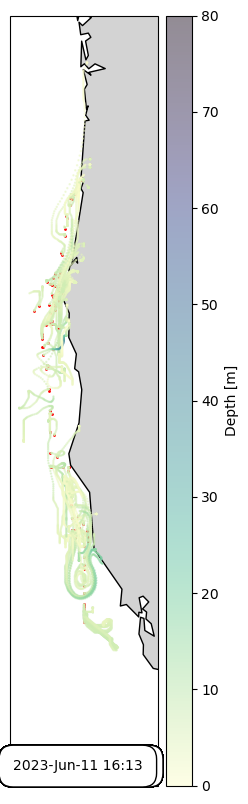

In [35]:
odt = 3
animation1 = animationfuction(outfile,odt)
HTML(animation1.to_jshtml())
#f = example_dataset_folder+"/backtrajectories_animation.mp4"
#FFwriter = animation.FFMpegWriter()
#animation1.save(f, writer = FFwriter)
